# Assignment 13: Customer Segmentation using Gaussian Mixture Model (GMM)
**Aim:** Perform customer segmentation on the Mall Customers dataset using the Gaussian Mixture Model (GMM) probabilistic clustering algorithm for both 1D and 2D feature configurations, and plot the corresponding cluster distributions.  
**Tools / Libraries:** `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn` (`sklearn.mixture.GaussianMixture`)  
**Programming Platform / Language:** Jupyter Notebook, Python

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load the Mall Customers dataset
df = pd.read_csv('Mall_Customers.csv')

# 2. Display the first few rows to inspect columns
print("Dataset Preview:")
display(df.head())

Dataset Preview:


,CustomerID,Gender,Age,Education,Annual Income (k$),Spending Score (1-100)
0,1,M,19,High School,15,39
1,2,M,21,Graduate,15,81
2,3,F,20,Graduate,16,6
3,4,F,23,High School,16,77
4,5,F,31,Uneducated,17,40


---
## 13a. GMM Customer Segmentation using a Single Feature
* **Feature Considered:** `Spending Score (1-100)`
* **Number of Clusters:** $K = 3$
* **Observation:** Because only one feature is used, data points will be distributed along a single line (1D strip plot).

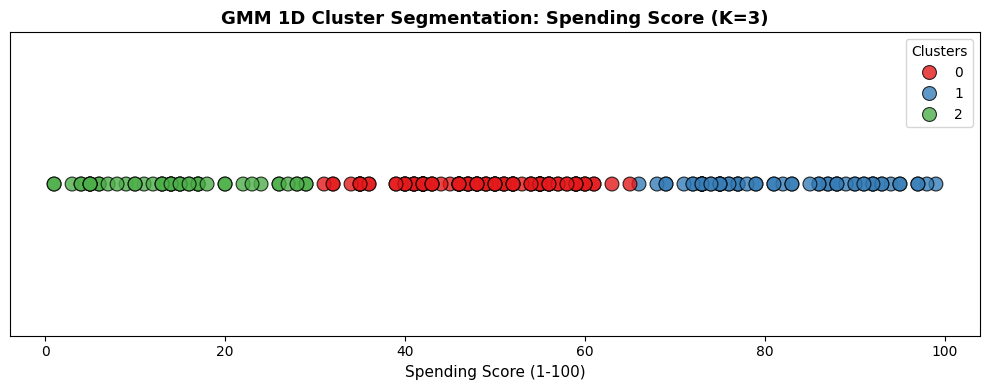

In [2]:
from sklearn.mixture import GaussianMixture

# 1. Extract single feature (reshaped as 2D array for sklearn)
X_1d = df[['Spending Score (1-100)']].values

# 2. Initialize and fit GMM with 3 components
gmm_1d = GaussianMixture(n_components=3, random_state=42)
labels_1d = gmm_1d.fit_predict(X_1d)

df['Cluster_1D'] = labels_1d

# 3. Plot the 1D cluster distribution (Line/Strip Plot)
plt.figure(figsize=(10, 4))
sns.scatterplot(
    x=df['Spending Score (1-100)'], 
    y=np.zeros_like(df['Spending Score (1-100)']), # Constant Y value for 1D line plot
    hue=df['Cluster_1D'], 
    palette='Set1', 
    s=100, 
    alpha=0.8, 
    edgecolor='k'
)

plt.title('GMM 1D Cluster Segmentation: Spending Score (K=3)', fontsize=13, fontweight='bold')
plt.xlabel('Spending Score (1-100)', fontsize=11)
plt.yticks([]) # Hide y-axis ticks since it's a 1D line plot
plt.ylabel('')
plt.legend(title='Clusters', loc='upper right')
plt.tight_layout()
plt.show()

---
## 13b. GMM Customer Segmentation using Two Features
* **Features Considered:** `Annual Income (k$)` and `Spending Score (1-100)`
* **Number of Clusters:** $K = 5$
* **Observation:** Utilizing two features yields a 2D scatter plot showing distinct probabilistic clusters.

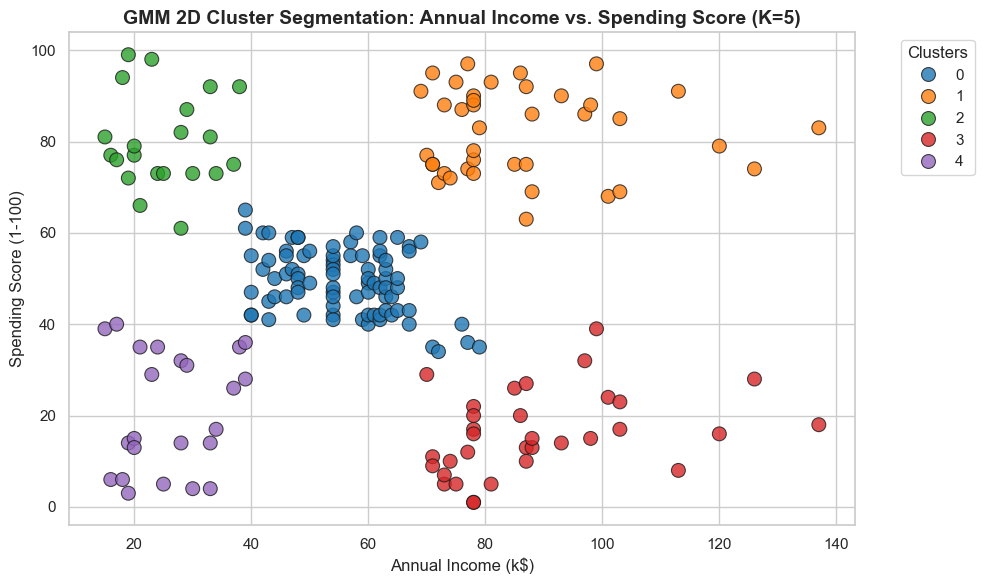

In [3]:
# 1. Extract two features
X_2d = df[['Annual Income (k$)', 'Spending Score (1-100)']].values

# 2. Initialize and fit GMM with 5 components
gmm_2d = GaussianMixture(n_components=5, random_state=42)
labels_2d = gmm_2d.fit_predict(X_2d)

df['Cluster_2D'] = labels_2d

# 3. Plot the 2D cluster distribution (Scatter Plot)
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

sns.scatterplot(
    x='Annual Income (k$)', 
    y='Spending Score (1-100)', 
    hue='Cluster_2D', 
    data=df, 
    palette='tab10', 
    s=100, 
    alpha=0.8, 
    edgecolor='k'
)

plt.title('GMM 2D Cluster Segmentation: Annual Income vs. Spending Score (K=5)', fontsize=14, fontweight='bold')
plt.xlabel('Annual Income (k$)', fontsize=12)
plt.ylabel('Spending Score (1-100)', fontsize=12)
plt.legend(title='Clusters', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()